<a href="https://colab.research.google.com/github/igornvidal/apollo_analytics_academy/blob/main/Rede_de_Passes_Argentina.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install statsbombpy pandas networkx matplotlib mplsoccer

Copas do Mundo disponíveis:
    competition_id season_name  season_id
30              43        2022        106
31              43        2018          3
32              43        1990         55
33              43        1986         54
34              43        1974         51
35              43        1970        272
36              43        1962        270
37              43        1958        269


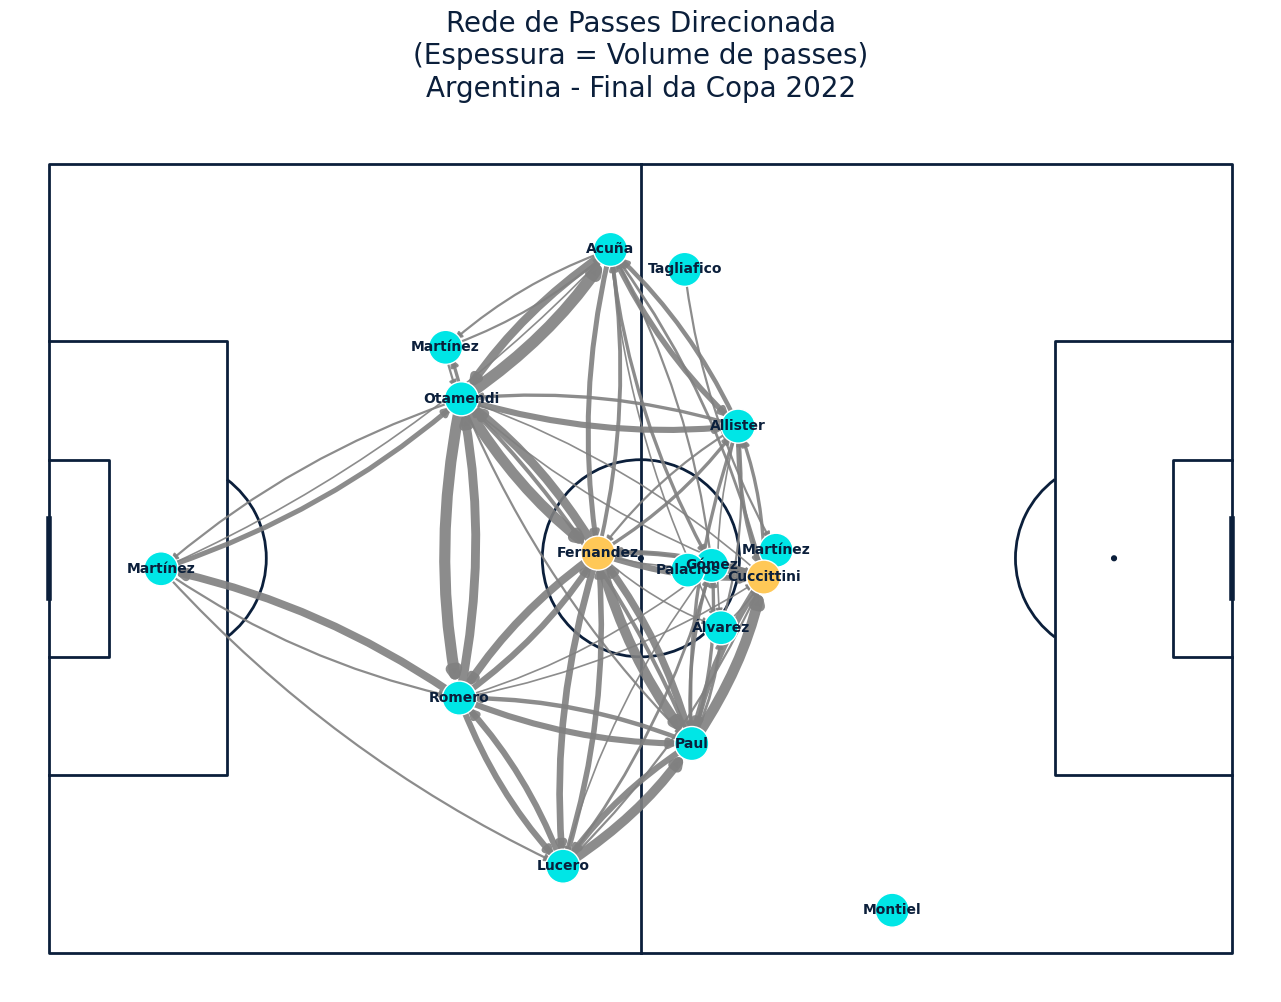

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from mplsoccer import Pitch
from statsbombpy import sb

# ==========================================
# 1. BUSCA DA COMPETIÇÃO E PARTIDA
# ==========================================
competicoes = sb.competitions()
copa_mundo = competicoes[competicoes['competition_name'] == 'FIFA World Cup']

# Imprime as temporadas disponíveis para você verificar o ID da Copa de 2026
print("Copas do Mundo disponíveis:")
print(copa_mundo[['competition_id', 'season_name', 'season_id']])

# Usaremos a final de 2022 (Argentina x França) como exemplo garantido.
# Para usar um jogo de 2026, basta trocar o competition_id, season_id e match_id.
ID_PARTIDA = 3869151

# ==========================================
# 2. FILTRAGEM DE EVENTOS (PASSES)
# ==========================================
eventos = sb.events(match_id=ID_PARTIDA)

# Filtrar apenas passes da Argentina
passes = eventos[(eventos['type'] == 'Pass') & (eventos['team'] == 'Argentina')]

# Na StatsBomb, um passe bem-sucedido tem o campo 'pass_outcome' como nulo (NaN)
passes_completos = passes[passes['pass_outcome'].isnull()].copy()

# ==========================================
# 3. PREPARAÇÃO DOS DADOS PARA O GRAFO
# ==========================================
# Desmembrar a coluna 'location' (que é uma lista [x, y]) em duas colunas separadas
passes_completos[['x', 'y']] = pd.DataFrame(passes_completos['location'].tolist(), index=passes_completos.index)

# NÓS: Calcular a posição média (x, y) de cada jogador para posicioná-lo no campo
nos = passes_completos.groupby('player').agg({'x': 'mean', 'y': 'mean'}).reset_index()

# ARESTAS: Contar o volume de passes entre cada par de jogadores (A -> B)
arestas = passes_completos.groupby(['player', 'pass_recipient']).size().reset_index(name='peso')

# ==========================================
# 4. CONSTRUÇÃO DA REDE (NETWORKX)
# ==========================================
G = nx.DiGraph() # Grafo direcionado

# Adicionando os nós com os atributos de posição
for _, row in nos.iterrows():
    # O mplsoccer inverte o Y para casar com a visualização, então mantemos a coordenada original aqui
    G.add_node(row['player'], pos=(row['x'], row['y']))

# Adicionando as arestas com o peso (volume de passes)
for _, row in arestas.iterrows():
    # Filtro opcional: só adicionar se tocaram mais de 2 vezes (limpa o visual)
    if row['peso'] > 2:
        G.add_edge(row['player'], row['pass_recipient'], weight=row['peso'])

# ==========================================
# 5. DATA STORYTELLING & PLOTAGEM
# ==========================================
# Desenhando o campo escuro (tipo 'statsbomb' garante a proporção 120x80)
pitch = Pitch(pitch_type='statsbomb', pitch_color='#ffffff', line_color='#0b1f3b')
fig, ax = pitch.draw(figsize=(14, 10))
fig.set_facecolor('#ffffff')

posicoes = nx.get_node_attributes(G, 'pos')
pesos = [G[u][v]['weight'] * 0.4 for u, v in G.edges()] # Ajuste de escala da grossura da linha

# Define custom colors for specific nodes
node_colors = []
target_players = ['Enzo Fernandez', 'Lionel Andrés Messi Cuccittini']
for node in G.nodes():
    if node in target_players:
        node_colors.append('#ffc857') # Custom color
    else:
        node_colors.append('#00e6e6') # Original color

# Desenhar Nós (Jogadores)
nx.draw_networkx_nodes(G, posicoes, ax=ax, node_color=node_colors, node_size=600, edgecolors='white', linewidths=1)

# Desenhar Arestas (Passes)
nx.draw_networkx_edges(G, posicoes, ax=ax, width=pesos, edge_color='grey', alpha=0.9,
                       arrows=True, arrowsize=10, connectionstyle='arc3,rad=0.1')

# Adicionar Nomes (Simplificando os nomes longos se necessário)
labels = {jogador: jogador.split(' ')[-1] for jogador in G.nodes()}
nx.draw_networkx_labels(G, posicoes, labels=labels, ax=ax, font_size=10, font_color='#0b1f3b', font_weight='bold')

plt.title("Rede de Passes Direcionada\n(Espessura = Volume de passes)\nArgentina - Final da Copa 2022", color='#0b1f3b', fontsize=20, pad=20, loc='left')
plt.show()